# Outliers and capped values

An **outlier** is a value far from the others. It may be an error, a rare but real case, or a member of a different population that doesn't belong in the table; what to do with it depends on which, and on the model that will use it. Before any of that, it has to be found, and the most common way of finding outliers is fooled by the outliers themselves.

## Ten values

Nine values between 20 and 28, and one of 100:

In [ ]:
import numpy as np
import pandas as pd

values = pd.Series([20, 21, 22, 23, 24, 25, 26, 27, 28, 100])
pd.Series({"mean": values.mean(), "median": values.median()})

mean      31.6
median    24.5
dtype: float64

The one extreme value pulls the mean up to 31.6, above nine of the ten values, while the median, 24.5, stays in the middle of the nine. Every statistic built on the mean (the standard deviation, a mean imputation, standardisation, a least-squares line) feels it.

## Rules for finding them

The usual rule standardises each value, measuring it in standard deviations from the mean (its *z-score*), and calls an outlier any value more than 3 standard deviations away:

In [ ]:
z_scores = (values - values.mean()) / values.std()
z_scores.round(2).to_list()

[-0.48, -0.44, -0.4, -0.36, -0.31, -0.27, -0.23, -0.19, -0.15, 2.83]

The 100 is 2.83 standard deviations from the mean: not an outlier, by this rule. Worse, with ten values no value can ever be: with the sample standard deviation that pandas uses, the largest z-score possible in a sample of $n$ values is $(n-1)/\sqrt{n}$, 2.85 for ten ($\sqrt{n-1}$, exactly 3, with the population standard deviation of NumPy and `StandardScaler`). The reason is that the outlier inflates the standard deviation that is supposed to reveal it. This is called **masking**, and it gets worse when there are several outliers.

Two rules built on statistics that one extreme value can't move:

- **The interquartile range (IQR) rule**, also called Tukey's fences: the middle half of the values lies between the first quartile $Q_1$ and the third $Q_3$; anything below $Q_1 - 1.5\,(Q_3 - Q_1)$ or above $Q_3 + 1.5\,(Q_3 - Q_1)$ is suspicious. It is the rule a box plot uses to draw separate points.
- **The robust z-score**: the distance to the median, divided by 1.4826 times the median of the absolute distances to the median (the *MAD*); the factor makes 1.4826 × MAD match the standard deviation when the data are normal. Above 3.5 is suspicious.

In [ ]:
first_quartile, third_quartile = values.quantile([0.25, 0.75])
upper_fence = third_quartile + 1.5 * (third_quartile - first_quartile)
median_absolute_deviation = (values - values.median()).abs().median()
robust_z_scores = (values - values.median()) / (1.4826 * median_absolute_deviation)
pd.Series({"upper fence of the IQR rule": upper_fence, "robust z-score of 100": robust_z_scores.iloc[-1]}).round(1)

upper fence of the IQR rule    33.5
robust z-score of 100          20.4
dtype: float64

Both find the 100 at once: it is far above the upper fence of 33.5, and its robust z-score is about 20. A rule only says which values to look at, though. Whether they are wrong is a question about the data.

## An error, a rare case or another population

The California housing data: one row per census district of 1990, with totals (rooms, bedrooms, people, households) and medians (age of the houses, income, house value). Downloaded the first time from the repository of Aurélien Géron's book:

In [ ]:
import tarfile
import urllib.request
from pathlib import Path

import pandas as pd

housing_csv = Path("data/housing/housing.csv")
if not housing_csv.exists():
    housing_csv.parent.mkdir(parents=True, exist_ok=True)
    archive, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/housing.tgz")
    with tarfile.open(archive) as tar:
        tar.extractall(path="data", filter="data")
housing = pd.read_csv(housing_csv)
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Rooms and people per household, the ratios that describe a typical home, have extremes worth reading one by one:

In [ ]:
housing = housing.assign(
    rooms_per_household=housing["total_rooms"] / housing["households"],
    people_per_household=housing["population"] / housing["households"],
)
housing[["rooms_per_household", "people_per_household"]].describe().round(1)

,rooms_per_household,people_per_household
count,20640.0,20640.0
mean,5.4,3.1
std,2.5,10.4
min,0.8,0.7
25%,4.4,2.4
50%,5.2,2.8
75%,6.1,3.3
max,141.9,1243.3


A typical district has about 5 rooms and 3 people per household. The maxima are 142 rooms and 1,243 people. Three kinds of extreme are mixed here.

**Errors.** Districts with more households than people, which is impossible, since every household has at least one member:

In [ ]:
housing.loc[housing["households"] > housing["population"], ["population", "households", "total_rooms"]]

,population,households,total_rooms
1235,3.0,4.0,18.0
5892,27.0,39.0,1116.0
5901,198.0,204.0,484.0


These are errors. A row that breaks a rule that holds everywhere is corrected if the true value can be found, and otherwise removed or set to missing, by a fixed rule, before anything is learned ([Finding the problems in a table](../../../pia/python-data-essentials/README.md) *(coming)*).

**Another population.** The districts with the most people per household:

In [ ]:
housing.nlargest(3, "people_per_household")[["longitude", "latitude", "population", "households", "people_per_household"]].round({"people_per_household": 1})

,longitude,latitude,population,households,people_per_household
4407,-121.98,38.32,7460.0,6.0,1243.3
13850,-120.51,40.41,4198.0,7.0,599.7
4002,-120.70,35.32,6532.0,13.0,502.5


Their coordinates are those of Vacaville, Susanville and San Luis Obispo, Californian towns with large state prisons. The census counts prisoners in a district's population, but not as households, so the ratio explodes. These districts are not wrong, but they are not neighbourhoods of homes either. If the model is meant to value residential districts, they are outside its scope, and leaving them out is a decision about the problem, to be written down, not a cleaning step.

**Rare but real.** The districts with the most rooms per household:

In [ ]:
housing.nlargest(3, "rooms_per_household")[["longitude", "latitude", "total_rooms", "households", "rooms_per_household"]].round({"rooms_per_household": 1})

,longitude,latitude,total_rooms,households,rooms_per_household
7150,-120.10,38.91,1561.0,11.0,141.9
18742,-120.08,38.80,1988.0,15.0,132.5
13539,-114.49,33.97,2809.0,45.0,62.4


Two of them are near Lake Tahoe, a mountain resort: holiday homes, with many rooms and few permanent households. They are real and part of the housing market. Removing them would teach the model that such districts don't exist.

## Rules on a real column

The rules of the ten values, on the rooms per household of the training rows (the split comes first, since the bounds found here may become part of the model):

In [ ]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(housing, test_size=0.2, random_state=42)
rooms = train["rooms_per_household"]
first_quartile, third_quartile = rooms.quantile([0.25, 0.75])
upper_fence = third_quartile + 1.5 * (third_quartile - first_quartile)
pd.Series({
    "rows": len(rooms),
    "above the upper fence": (rooms > upper_fence).sum(),
    "z-score above 3": ((rooms - rooms.mean()).abs() / rooms.std() > 3).sum(),
    "upper fence": round(upper_fence, 1),
}, dtype=object)

rows                     16512
above the upper fence      375
z-score above 3            106
upper fence                8.5
dtype: object

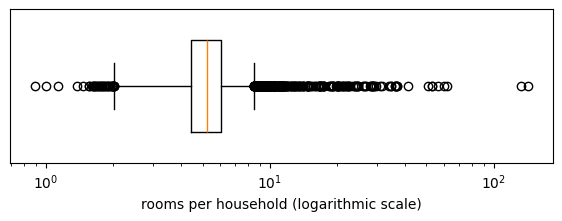

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 2))
plt.boxplot(rooms, orientation="horizontal", widths=0.6)
plt.xscale("log")
plt.yticks([])
plt.xlabel("rooms per household (logarithmic scale)");

The IQR rule flags 375 districts above 8.5 rooms per household (and some below the lower fence): large houses, mostly, not errors. The z-score rule flags only 106, those above 13.1 rooms: the long tail inflates the standard deviation, the masking seen above, now on real data. Rules like these assume that values are spread roughly symmetrically around the centre. This column has a long right tail (many values a little above the centre, a few very far), and on such a column they flag the tail itself. The box plot needs a logarithmic scale to be readable at all. A long tail is usually better handled by transforming the column than by cutting it ([Skewed distributions and the log transform](skewed_distributions.ipynb)); the rules are a list of values to look at, not of values to remove.

## Capped values

Some extremes are not in the data because someone removed them before it was published. The histograms of the house value (the target) and of the median age of the houses:

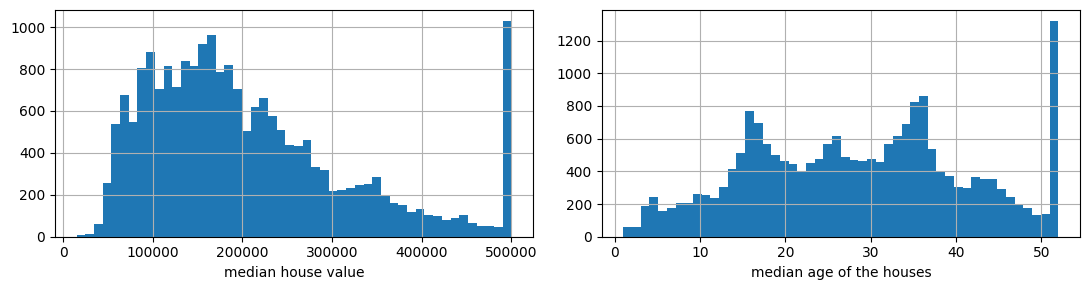

In [ ]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3))
housing["median_house_value"].hist(bins=50, ax=axes[0])
axes[0].set_xlabel("median house value")
housing["housing_median_age"].hist(bins=50, ax=axes[1])
axes[1].set_xlabel("median age of the houses")
figure.tight_layout()

In [ ]:
pd.Series({
    "districts with a value of 500,001": (housing["median_house_value"] == 500_001).sum(),
    "districts with an age of 52": (housing["housing_median_age"] == 52).sum(),
    "districts with an income of 15.0001": (housing["median_income"] == 15.0001).sum(),
})

districts with a value of 500,001       965
districts with an age of 52            1273
districts with an income of 15.0001      49
dtype: int64

Each column ends in a tall bar: every value above a limit was replaced by the limit. The 965 districts at 500,001 dollars are worth *at least* that much, by an unknown amount; the same goes for the ages of 52 years and the incomes of 15.0001 (tens of thousands of dollars). Such values are **capped**, or **censored**: not outliers, but values whose true size was hidden.

A capped **target** is the more serious case. A model trained on it learns that no district is worth more than 500,001 dollars: a decision tree or a random forest predicts averages of training targets, so it can never predict more, and no model can be evaluated on how wrong it is above the cap, because the true values are unknown. Three ways out:

- Get the real values, when the source has them.
- Remove the capped districts from the training **and** the test data, and state that the model is valid only below 500,000 dollars, a condition that can't be checked before predicting, since the value is what is predicted.
- Keep them, if nothing above the cap will ever be asked of the model.

A capped **feature** is milder: the feature stops growing at its limit, and the model can't tell 52 years from 80. A column that flags the capped rows (`housing_median_age == 52`) lets it treat them as a group of their own.

## What to do with an outlier

| Treatment | What it does | When |
| --- | --- | --- |
| Keep | Nothing | Rare but real values, and models that aren't sensitive to them (trees) |
| Correct | Replaces the value with the true one | Errors whose true value can be found |
| Remove the row, or set the value to missing | | Errors that can't be corrected (an age above 120); rows outside the model's scope (a decision about the problem) |
| Clip at a fixed bound | Replaces every value beyond a bound known from the domain with the bound | Real values beyond a bound the problem doesn't distinguish (more than 10 bathrooms counted as 10; the range of a sensor) |
| Winsorise | Clips at percentiles (for example the 1st and 99th) learned from the training rows | Extreme values that are real but would dominate a model sensitive to them |
| Transform | A logarithm brings a long tail closer | Long right tails ([Skewed distributions](skewed_distributions.ipynb)) |
| Scale robustly | Centres on the median and divides by the interquartile range | Models that need scaling, on columns with extremes ([Scaling numerical features](../feature_scaling.ipynb)) |
| Use a robust model | A loss that doesn't square large errors, such as a tree with `criterion="absolute_error"` | When the extremes are in the target |
| Flag | Adds a column that marks the extreme or capped rows | Whenever being extreme may itself be informative |

Three of these, at work. **Clipping before min-max scaling.** Min-max scaling maps the smallest value to 0 and the largest to 1; with the 100 present, the nine others are squeezed into the bottom tenth:

In [ ]:
from sklearn.preprocessing import MinMaxScaler

pd.DataFrame({
    "as recorded": MinMaxScaler().fit_transform(values.to_frame()).ravel(),
    "clipped at 30": MinMaxScaler().fit_transform(values.clip(upper=30).to_frame()).ravel(),
}).round(2).T

,0,1,2,3,4,5,6,7,8,9
as recorded,0.0,0.01,0.03,0.04,0.05,0.06,0.08,0.09,0.1,1.0
clipped at 30,0.0,0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.8,1.0


Clipped, the nine ordinary values spread over the whole range again. Whether clipping is right depends on what the 100 is: a typo should be corrected or removed; a real value is distorted by clipping, and a robust scaler or a transformation may be better.

**Winsorising inside the pipeline.** The bounds of a winsorisation are learned from the data, so, like a median used to fill gaps, they must be learned from the training rows only and then applied unchanged to new rows ([Where data preparation ends](../where_preparation_ends.ipynb)). scikit-learn has no winsorising transformer, but one takes a few lines: `fit` learns the bounds, `transform` clips at them:

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin


class Winsorizer(TransformerMixin, BaseEstimator):
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X, self.lower_quantile, axis=0)
        self.upper_bounds_ = np.nanquantile(X, self.upper_quantile, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_bounds_, self.upper_bounds_)

Fitted on the training rows, and applied to the test rows:

In [ ]:
winsorizer = Winsorizer().fit(train[["rooms_per_household"]])
test_winsorized = winsorizer.transform(test[["rooms_per_household"]])
pd.DataFrame({
    "learned bounds": [winsorizer.lower_bounds_[0], winsorizer.upper_bounds_[0]],
    "test rows before": [test["rooms_per_household"].min(), test["rooms_per_household"].max()],
    "test rows after": [test_winsorized.min(), test_winsorized.max()],
}, index=["lowest", "highest"]).round(2)

,learned bounds,test rows before,test rows after
lowest,2.59,0.85,2.59
highest,10.42,62.42,10.42


The bounds come from the training rows (between about 2.6 and 10.4 rooms per household) and are applied to the test rows, whose extremes are pulled in to them. Inside a `Pipeline`, `fit` runs on the training rows only, as for any other transformer ([California housing with pipelines](../../supervised-learning/basic-workflows/california_with_pipelines.ipynb)).

**A robust model.** Ten points on a line, and one point far above it:

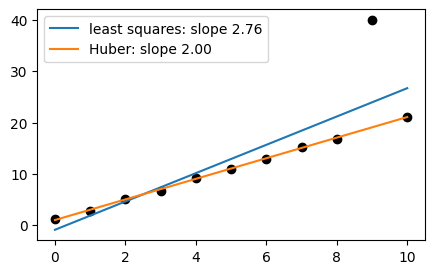

In [ ]:
from sklearn.linear_model import HuberRegressor, LinearRegression

x = np.arange(11, dtype=float).reshape(-1, 1)
y = 2 * x.ravel() + 1 + np.array([0.3, -0.2, 0.1, -0.4, 0.2, 0.0, -0.1, 0.3, -0.3, 0.1, 0.0])
y[9] = 40
least_squares = LinearRegression().fit(x, y)
huber = HuberRegressor().fit(x, y)

plt.figure(figsize=(5, 3))
plt.scatter(x, y, color="black")
plt.plot(x, least_squares.predict(x), label=f"least squares: slope {least_squares.coef_[0]:.2f}")
plt.plot(x, huber.predict(x), label=f"Huber: slope {huber.coef_[0]:.2f}")
plt.legend();

The true slope is 2. Least squares minimises the *squared* errors, so the one point far from the line, whose error squared is huge, pulls the whole line towards it. The Huber loss squares small errors but only takes the absolute value of large ones, so the far point counts much less, and the line follows the other ten. When the extremes are in the target and are real, a loss of this kind, or the absolute error, is often better than removing them; [Measuring a regression model's error](../../supervised-learning/evaluation/regression_metrics.ipynb) explains how squared and absolute errors weigh large errors.

## Strange in combination

Every rule above looks at one column at a time. Some rows are ordinary in each column and strange only in combination: more households than people is an example, each number plausible on its own. With many columns, finding such rows is the job of anomaly detection, models that learn what ordinary rows look like and score how far each row is from it, such as isolation forests (Unsupervised learning *(coming)*).